# This is an example notebook to show how our code can be used for a centralities scenario

## Imports

We first import the required modules

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from SuSceMod.simulation import logger, data_utilities, input_handling, scenarios

## Setup of the simulation

Besides the built-up maps and the suitability maps, this scenario needs two more rasters. Both must be on the same grid as the built-up maps, and are placed in `input_rasters`:
- `BU_centralities.tif`: 1 inside the centralities and 0 outside
- `ex_Zone_eau_binary.tif`: 1 for water. These cells can never change

In [2]:
input_folder = './input_rasters/'

output_folder = './output/centralities/'
os.makedirs(output_folder, exist_ok=True)

suitability_maps_folder = './suitability_maps/'

centralities_path = input_folder + 'BU_centralities.tif'
water_path = input_folder + 'ex_Zone_eau_binary.tif'

missing = [path for path in (centralities_path, water_path) if not os.path.exists(path)]
if missing:
    raise FileNotFoundError(f'Add these rasters before running: {missing}')

The printed output of the simulation is also saved in a log file in the output folder

In [3]:
log_file = os.path.join(output_folder, 'simulation.log')
open(log_file, 'w').close()  # start a fresh log
logger.setup_logger(log_file, log_time=False)

The Growth-As-Usual (GAU) scenario runs from 2020 to 2030. From 2030, the centralities scenario starts from the GAU map of 2030 and runs until 2050

In [4]:
initial_year = 2020
policy_year = 2030
final_year = 2050

In [5]:
prob_years = [2010, 2020]
change_years = [2010, 2020]

In [6]:
initial_built_up_map = data_utilities.load_raster_data(
    input_folder + f'BU_{initial_year}.tif'
)
central_zones = data_utilities.load_raster_data(centralities_path)
water_zone = data_utilities.load_raster_data(water_path)

Path to the suitability maps, to guide the allocation

In [7]:
suitability_maps_path = suitability_maps_folder + f"{str(prob_years[0])[-2:]}_{str(prob_years[1])[-2:]}/"
prob_maps_dict, prob_map_paths = input_handling.load_prob_maps(suitability_maps_path, prob_years)

Give the paths to the maps to calculate the change maps, and in turn, the demand

In [8]:
initial_demand_map = input_folder + f'BU_{change_years[0]}.tif'
final_demand_map   = input_folder + f'BU_{change_years[1]}.tif'

change_maps_dict, classes = input_handling.calculate_change_maps(
    initial_demand_map, final_demand_map
)

In [9]:
annual_rates, period_counts, crosstab_df = input_handling.calculate_change_rates(
    change_maps_dict, change_years
)


Crosstab (counts, incl. no-change on diagonal):


         0      1       2      3
0  1381843   4906    3538    744
1        0  72337    5613    202
2        0      0  159056   3665
3        0      0       0  58216



Annual change rates (cells/year):


    0 -> 1: 490.6


    0 -> 2: 353.8


    0 -> 3: 74.4


    1 -> 2: 561.3


    1 -> 3: 20.2


    2 -> 3: 366.5


## Share of the development inside the centralities in the past

To keep the historical split of the development, we first measure it. We lay the centralities over the maps of 2010 and 2020, and calculate which share of the expansion (empty cells that became built-up) and which share of the densification (cells that became denser) happened inside them

In [10]:
historical_central_shares = input_handling.calculate_central_shares(
    data_utilities.load_raster_data(input_folder + f'BU_{change_years[0]}.tif'),
    data_utilities.load_raster_data(input_folder + f'BU_{change_years[1]}.tif'),
    central_zones
)
print(f'Share inside the centralities between {change_years[0]} and {change_years[1]}: '
      f'expansion {historical_central_shares[0]}, densification {historical_central_shares[1]}')

Share inside the centralities between 2010 and 2020: expansion 0.13, densification 0.26


## Growth-As-Usual until 2030

The demand stays as observed, which is the Growth-As-Usual scenario, and the share of the development inside the centralities is kept at its historical value every year. Cells in water are never changed. We only keep the map of 2030, to start the centralities scenario from

In [11]:
gau_maps, gau_paths, gau_counts = scenarios.simulate_growth_based_scenario(
    initial_year,
    policy_year,
    initial_built_up_map,
    prob_maps_dict,
    annual_rates,
    output_folder,
    randomness='gumbel',
    seed=2118,
    water_zone=water_zone,
    central_zones=central_zones,
    central_shares=historical_central_shares
)


Demands (cells/year):


    0 -> 1: 490.6


    0 -> 2: 353.8


    0 -> 3: 74.4


    1 -> 2: 561.3


...


------------------------------------------------------



Year 2030: Updated built-up map summary (value: count):


{0.0: 1372653, 1.0: 76343, 2.0: 173697, 3.0: 67427, 'nan': 2004749}



Changes from previous year summary (value: count):


{0: -919, 1: -90, 2: 549, 3: 460}


## Share of the development inside the centralities in 2030

The centralities scenario starts from here, so we measure the share again on the map of 2030, by laying the centralities over the maps of 2020 and 2030. It should be close to the historical share, and it tells us how much the allocation has to shift to reach the target

In [12]:
initial_central_shares = input_handling.calculate_central_shares(
    initial_built_up_map, gau_maps[policy_year], central_zones
)
print(f'Share inside the centralities in {policy_year}: expansion {initial_central_shares[0]}, densification {initial_central_shares[1]}')

Share inside the centralities in 2030: expansion 0.13, densification 0.26


The policy aims for 75% of the development inside the centralities by 2050, for both expansion and densification

In [13]:
final_central_shares = [0.75, 0.75]

## Running the simulation

The total demand stays the same every year, and only its location changes. The share inside the centralities moves in equal yearly steps, from its value in 2030 to 75% in 2050. Allocating 75% right from the start is not realistic, hence the gradual change

In [14]:
simulated_maps, output_paths, class_counts_dict = scenarios.simulate_centralities_scenario(
    policy_year,
    final_year,
    gau_maps[policy_year],
    prob_maps_dict,
    annual_rates,
    central_zones,
    initial_central_shares,
    output_folder,
    final_central_shares=final_central_shares,
    water_zone=water_zone,
    randomness='gumbel',
    seed=2118
)


Demands (cells/year):


    0 -> 1: 490.6


    0 -> 2: 353.8


    0 -> 3: 74.4


    1 -> 2: 561.3


...


------------------------------------------------------



Year 2050: Updated built-up map summary (value: count):


{0.0: 1354273, 1.0: 74543, 2.0: 184677, 3.0: 76627, 'nan': 2004749}



Changes from previous year summary (value: count):


{0: -919, 1: -90, 2: 549, 3: 460}


In [15]:
counts_csv_file = os.path.join(output_folder, f"class_counts_{policy_year}_{final_year}.csv")
data_utilities.save_counts_to_csv(class_counts_dict, counts_csv_file)

A template raster is required to save the simulated rasters with proper extent and boundaries. We can simply use the built-up map of the initial year for this purpose

In [16]:
template_raster_path = input_folder + f'BU_{initial_year}.tif'

In [17]:
for year in simulated_maps.keys():
    data_utilities.writeraster(template_raster_path, output_paths[year], simulated_maps[year])

## View results of the simulation

### Share of the development inside the centralities over time

For every year, we measure the share of the expansion and of the densification that happened inside the centralities. The dashed line is the target

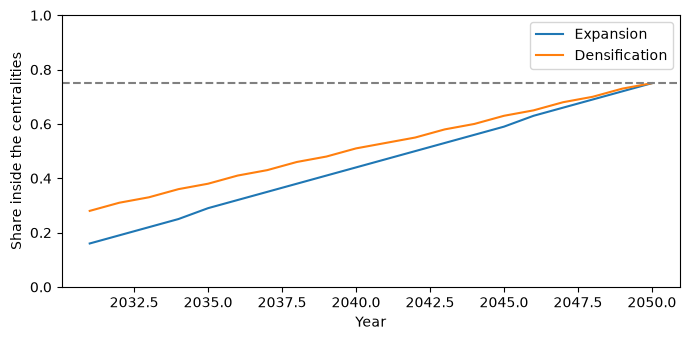

In [18]:
shares = {}
previous_map = gau_maps[policy_year]
for year in sorted(simulated_maps):
    shares[year] = input_handling.calculate_central_shares(previous_map, simulated_maps[year], central_zones)
    previous_map = simulated_maps[year]
shares_df = pd.DataFrame(shares, index=['Expansion', 'Densification']).T

ax = shares_df.plot(figsize=(7, 3.5))
ax.axhline(final_central_shares[0], linestyle='--', color='grey')
ax.set_ylim(0, 1)
ax.set_xlabel('Year')
ax.set_ylabel('Share inside the centralities')
plt.tight_layout()
plt.show()

### Understanding the trend of each density class over time

Convert the class counts dictionary `class_counts_dict` to a dataframe for easier processing

In [19]:
class_counts_df = data_utilities.counts_to_df(class_counts_dict, exclude_nan=True)

We can now filter to get the required values. Here, for example, we look at the year 2040

In [20]:
class_counts_df[class_counts_df['year']==2040]

,year,category,count
36,2040,0.0,1363463
37,2040,1.0,75443
38,2040,2.0,179187
39,2040,3.0,72027


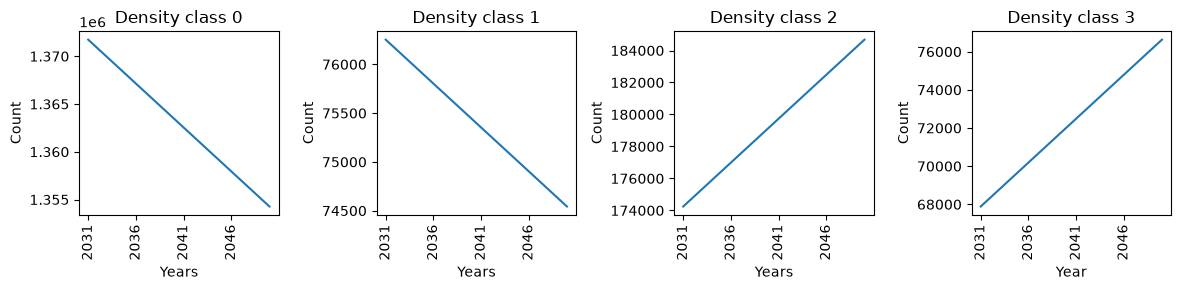

In [21]:
categories = class_counts_df["category"].unique()
n = len(categories)

fig, axes = plt.subplots(1, n, figsize=(12, 3), sharex=True)

for ax, cat in zip(axes, categories):
    sub = class_counts_df[class_counts_df["category"] == cat]
    ax.plot(sub["year"], sub["count"])
    ax.set_title(f"Density class {int(cat)}")
    ax.set_ylabel("Count")
    ax.set_xlabel("Years")
    ax.tick_params(axis="x", labelrotation=90)
    years = range(policy_year + 1, final_year + 1, 5)
    ax.set_xticks(years)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

### Quick visualization of the simulated rasters

For example, we look at the density classes for the raster of the final year

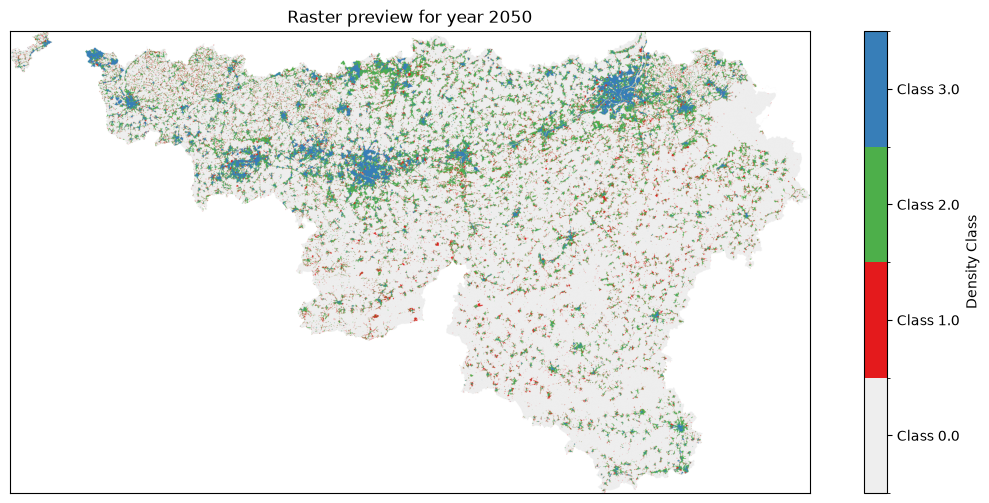

In [22]:
example_year = final_year

example_raster = data_utilities.load_raster_data(output_folder + f"sim_{example_year}.tif")
data_utilities.plot_raster_classes(
    example_raster, 
    colors=["#eeeeee", "#e41a1c", "#4daf4a", "#377eb8"], 
    title=f'Raster preview for year {example_year}'
)